In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"C:\Pedro\curso\labs\amz_uk_price_prediction_dataset.csv")


In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


Part 1: Understanding Product Categories

1-Frequency Tables:

In [5]:
# Frequency table of product categories
category_freq = df['category'].value_counts().reset_index()
category_freq.columns = ['Category', 'Listing_Frequency']

print(category_freq.head(10))

                                 Category  Listing_Frequency
0                       Sports & Outdoors             836265
1                                  Beauty              19312
2  Handmade Clothing, Shoes & Accessories              19229
3                             Bath & Body              19092
4                          Birthday Gifts              18978
5            Manicure & Pedicure Products              18940
6                               Skin Care              18769
7                                 Make-up              18756
8                               Hair Care              18735
9                              Fragrances              18564


In [6]:
# top 5 most listed product categories

top_5_categories = category_freq.head(5)
print("Top 5 Most Listed Product Categories:")
print(top_5_categories)

Top 5 Most Listed Product Categories:
                                 Category  Listing_Frequency
0                       Sports & Outdoors             836265
1                                  Beauty              19312
2  Handmade Clothing, Shoes & Accessories              19229
3                             Bath & Body              19092
4                          Birthday Gifts              18978


2-Visualizations:

In [7]:
import matplotlib.pyplot as plt

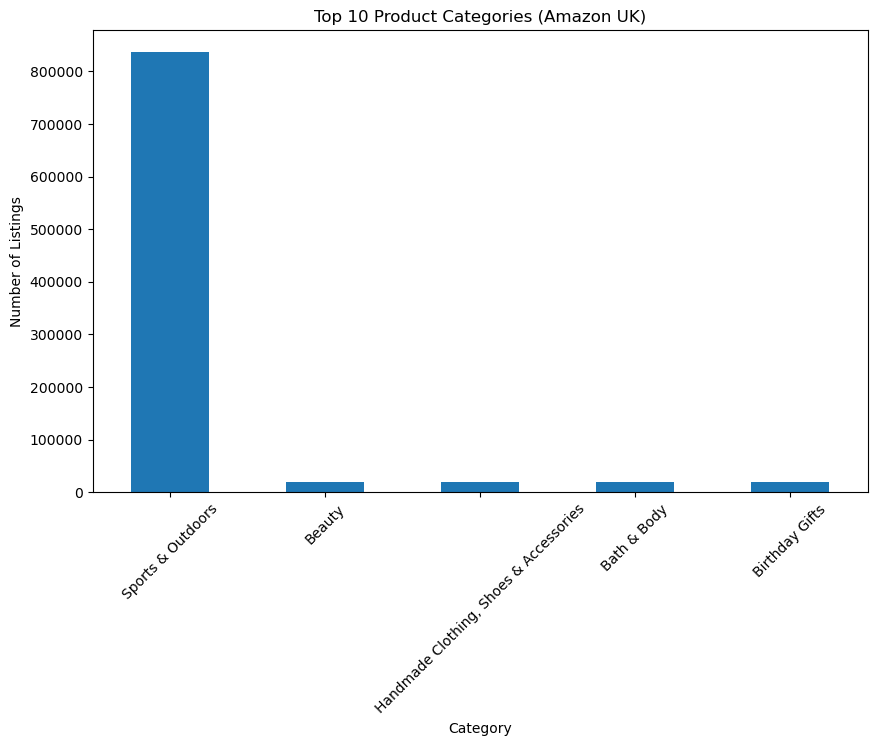

In [8]:
plt.figure(figsize=(10,6))
df['category'].value_counts().head(5).plot(kind='bar')
plt.title("Top 10 Product Categories (Amazon UK)")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

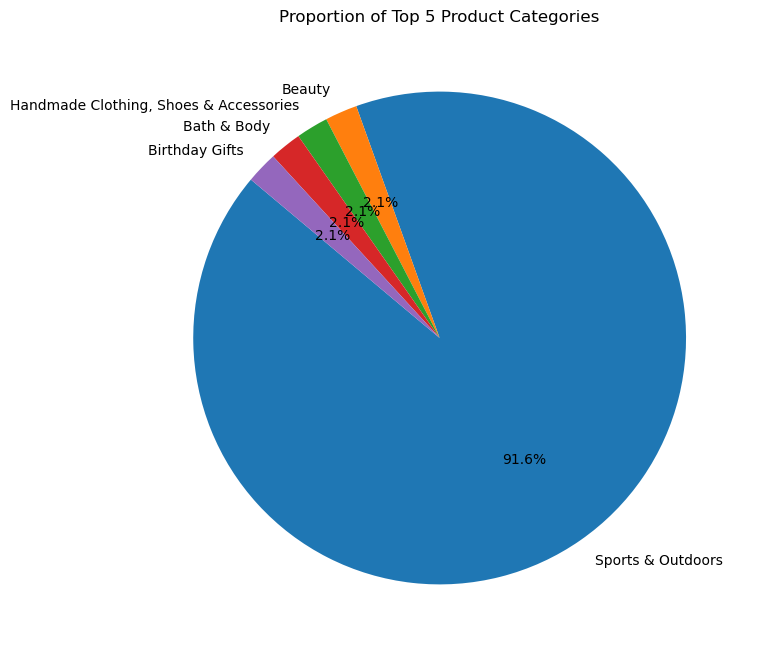

In [9]:
top_categories = df['category'].value_counts().head(5)

plt.figure(figsize=(8,8))
top_categories.plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title("Proportion of Top 5 Product Categories")
plt.ylabel("") 
plt.show()

Part 2: Delving into Product Pricing

1-Measures of Centrality:

In [10]:
# Drop missing or invalid prices
df = df[df['price'].notnull()]

mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean Price: {mean_price:.2f}")
print(f"Median Price: {median_price:.2f}")
print(f"Mode Price: {mode_price:.2f}")

Mean Price: 89.24
Median Price: 19.09
Mode Price: 9.99


The mean is much higher than the median price, this indicates that some very expensive products are inflating the average.
The mode value suggests that the most common products are in the low-price range.

2. Measures of Dispersion:

In [11]:
price_variance = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Variance: {price_variance:.2f}")
print(f"Standard Deviation: {price_std:.2f}")
print(f"Range: {price_range:.2f}")
print(f"IQR: {iqr:.2f}")

Variance: 119445.49
Standard Deviation: 345.61
Range: 100000.00
IQR: 36.00


Values of variance and standard deviation are showing that there is a very large spread.
The range value show us that there is outliers.
The value of iqr is showing that middle 50% of products are within a much smaller, more typical range

3-Shape of the Distribution:

In [12]:
from scipy.stats import skew, kurtosis

In [14]:
# Drop missing values if any
stars = df['stars'].dropna()

star_skewness = skew(stars)
star_kurtosis = kurtosis(stars)

print(f"Skewness (Stars): {star_skewness:.2f}")
print(f"Kurtosis (Stars): {star_kurtosis:.2f}")

Skewness (Stars): 0.08
Kurtosis (Stars): -1.93


Since skewness is very close to 0, the distribution of stars is nearly symmetric.

Negative kurtosis indicates a platykurtic distribution, flatter than normal. This means ratings are more spread out across different star levels, with fewer extreme peaks or outliers than a normal distribution.

4-Visualizations:

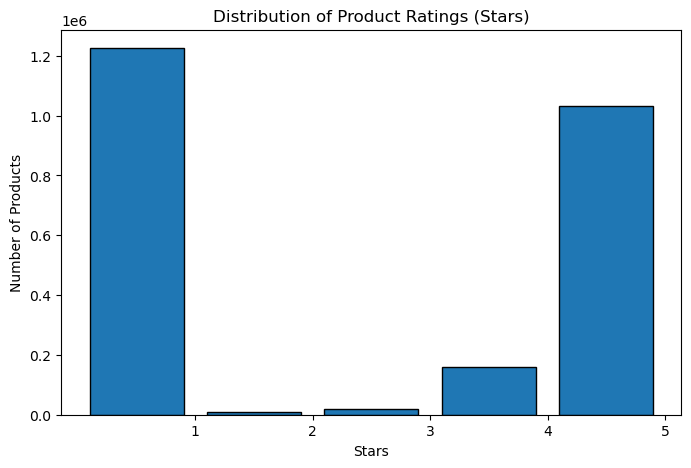

In [15]:
plt.figure(figsize=(8,5))
df['stars'].dropna().plot(kind='hist', bins=5, edgecolor='black', rwidth=0.8)

plt.title("Distribution of Product Ratings (Stars)")
plt.xlabel("Stars")
plt.ylabel("Number of Products")
plt.xticks([1,2,3,4,5])
plt.show()